# EQCLib と CHIMES の非平衡熱化学比較

両コードの非平衡モードを使います。無照射・固定密度の4条件で、温度・冷却率・化学種の時間履歴と、1セル更新あたりの CPU 時間を比較します。比較スクリプトが `test/out/chimes/optically-thin/` に出力した CSV から図を描きます。セルは先頭から順に実行してください。別の計算結果を使う場合は、最初のコードセルの `data_dir` を変更してください。

[初期条件と計測方法](../test/chimes/optically-thin/README.md)

In [1]:
%matplotlib inline

import csv
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

cwd = Path.cwd().resolve()
eqclib_dir = next(
    (directory for directory in (cwd, *cwd.parents, cwd / "EQCLib")
     if (directory / "src/ChemicalEquilibriumCooling.h").is_file()),
    None,
)
if eqclib_dir is None:
    raise FileNotFoundError("EQCLib のリポジトリ内でノートブックを実行してください。")
data_dir = eqclib_dir / "test/out/chimes/optically-thin"

CASES = {
    "hydrogen": ("Pure H, fixed temperature", "x_HII", r"$n(\mathrm{H}^+)/n_\mathrm{H}$"),
    "recombining": ("Recombining gas", "x_HII", r"$n(\mathrm{H}^+)/n_\mathrm{H}$"),
    "molecular": ("Molecular gas", "f_H2", r"$2n(\mathrm{H}_2)/n_\mathrm{H}$"),
    "hot": ("Hot gas", "x_OIII", r"$n(\mathrm{O}^{2+})/n_\mathrm{O}$"),
}
STYLES = {
    "EQCLib": {"color": "#12627a", "linestyle": "-", "label": "EQCLib"},
    "CHIMES": {"color": "#b85223", "linestyle": "--", "label": "CHIMES"},
}
STEPS = (10, 1000, 100000)


def read_csv(path):
    with path.open(newline="") as file:
        return list(csv.DictReader(file))


def style_axes(axis):
    axis.set_axisbelow(True)
    axis.grid(alpha=.22)
    axis.spines[["top", "right"]].set_visible(False)


legend = [Line2D([0], [0], linewidth=2, **style) for style in STYLES.values()]

## 温度・冷却率・化学組成の時間履歴

上から温度、体積冷却率、条件ごとの化学種分率を示します。経過時間は対数軸で、`history.csv` に記録した初期時刻（0年）の次の時点から描画します。

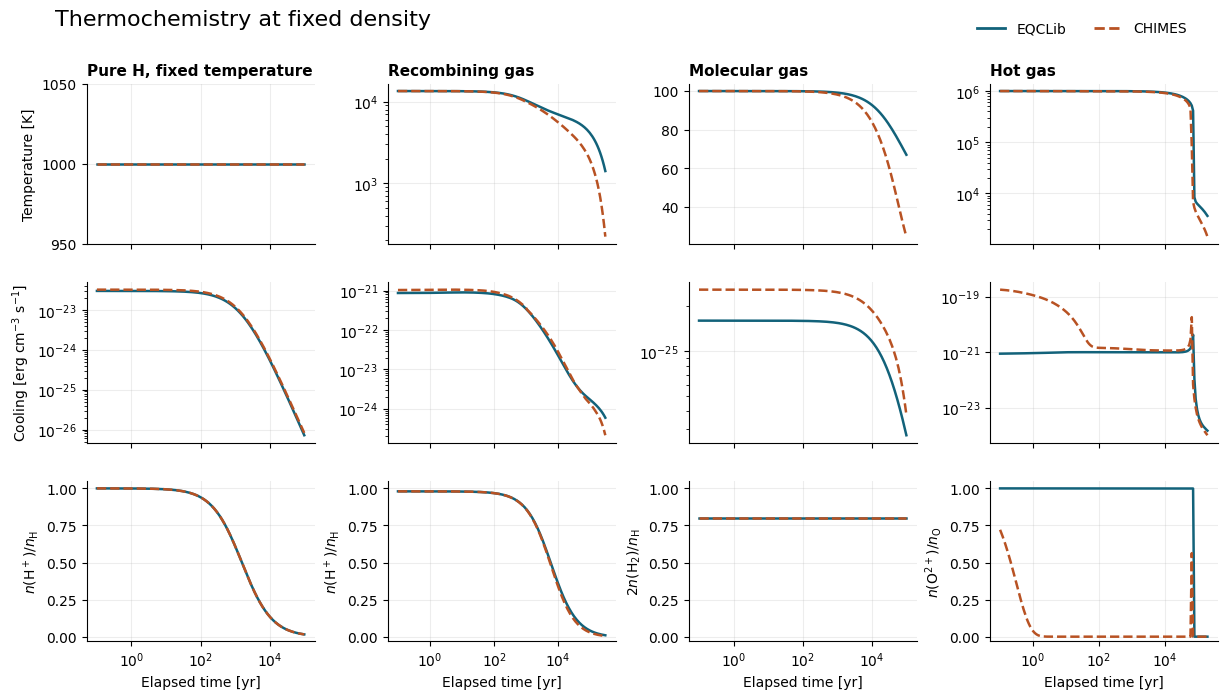

In [2]:
def plot_history(directory, legend):
    histories = defaultdict(list)
    for row in read_csv(directory / "history.csv"):
        if float(row["time_yr"]) > 0:
            histories[row["case"], row["solver"]].append(row)
    figure, axes = plt.subplots(3, 4, figsize=(12.5, 7.1), sharex="col")
    for column, (case, (title, fraction, fraction_label)) in enumerate(CASES.items()):
        axes[0, column].set_title(title, fontsize=11, loc="left", fontweight="bold")
        fields = ("T_K", "cooling", fraction)
        for row_index, field in enumerate(fields):
            axis = axes[row_index, column]
            for solver, style in STYLES.items():
                series = histories[case, solver]
                if len(series) != 160:
                    raise ValueError(f"Incomplete time history for {case} {solver}")
                times = [float(row["time_yr"]) for row in series]
                # Express hot O III relative to total oxygen, whose abundance is 5e-4 per H.
                scale = 5e-4 if field == "x_OIII" else 1.
                values = [float(row[field]) / scale for row in series]
                axis.plot(times, values, linewidth=1.8, **style)
            axis.set_xscale("log")
            if field == "cooling" or (field == "T_K" and case in ("hot", "recombining")):
                axis.set_yscale("log")
            if field == "T_K" and case == "hydrogen":
                axis.set_ylim(950, 1050)
                axis.set_yticks([950, 1000, 1050])
            if row_index == 2:
                axis.set_ylim(-.03, 1.05)
                axis.set_xlabel("Elapsed time [yr]")
                axis.set_ylabel(fraction_label)
            style_axes(axis)
    axes[0, 0].set_ylabel("Temperature [K]")
    axes[1, 0].set_ylabel(r"Cooling [erg cm$^{-3}$ s$^{-1}$]")
    figure.suptitle("Thermochemistry at fixed density", x=.055, y=.98, ha="left", fontsize=16)
    figure.legend(handles=legend, loc="upper right", bbox_to_anchor=(.97, .98), ncol=2, frameon=False)
    figure.subplots_adjust(left=.08, bottom=.09, right=.985, top=.875, wspace=.32, hspace=.24)
    return figure


history_figure = plot_history(data_dir, legend)
plt.show()

## 1セル更新の CPU 時間

時間刻みは10年・1,000年・10万年です。各点は単一コアで計測した5バッチの中央値、エラーバーは最小値から最大値までを示します。

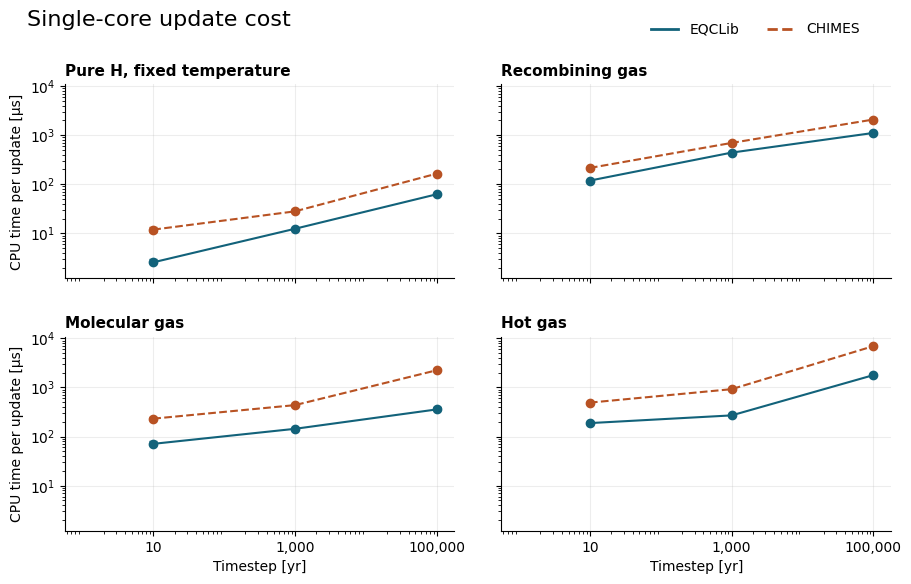

In [3]:
def plot_speed(summaries, legend):
    figure, axes = plt.subplots(2, 2, figsize=(9.5, 6.2), sharex=True, sharey=True)
    for index, (case, (title, _, _)) in enumerate(CASES.items()):
        axis = axes.flat[index]
        rows = [summaries[case, step] for step in STEPS]
        for solver, style in STYLES.items():
            prefix = solver.lower()
            values = [float(row[f"{prefix}_cpu_us"]) for row in rows]
            low = [value - float(row[f"{prefix}_min_us"]) for row, value in zip(rows, values)]
            high = [float(row[f"{prefix}_max_us"]) - value for row, value in zip(rows, values)]
            axis.errorbar(STEPS, values, yerr=(low, high), marker="o", capsize=3, **style)
        axis.set_title(title, fontsize=11, loc="left", fontweight="bold")
        axis.set_xscale("log")
        axis.set_yscale("log")
        axis.set_xticks(STEPS, ["10", "1,000", "100,000"])
        if index % 2 == 0:
            axis.set_ylabel("CPU time per update [µs]")
        if index >= 2:
            axis.set_xlabel("Timestep [yr]")
        style_axes(axis)
    figure.suptitle("Single-core update cost", x=.07, y=.96, ha="left", fontsize=16)
    figure.legend(handles=legend, loc="upper right", bbox_to_anchor=(.96, .96), ncol=2, frameon=False)
    figure.subplots_adjust(left=.11, bottom=.12, right=.98, top=.84, wspace=.12, hspace=.30)
    return figure


summaries = {(row["case"], int(row["dt_yr"])): row for row in read_csv(data_dir / "summary.csv")}
speed_figure = plot_speed(summaries, legend)
plt.show()